#**RQ 1**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3 as sql

In [21]:
#TAKE DATA FROM SQL VIEW
conn = sql.connect("../data/olist.db")
query = """SELECT *
FROM delivery_performance"""
data = pd.read_sql_query(query, conn)
conn.close()

In [22]:
#DATA INSPECTION
print(data.info())


<class 'pandas.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       96470 non-null  str  
 1   customer_id                    96470 non-null  str  
 2   order_status                   96470 non-null  str  
 3   order_purchase_timestamp       96470 non-null  str  
 4   order_approved_at              96456 non-null  str  
 5   order_delivered_carrier_date   96469 non-null  str  
 6   order_delivered_customer_date  96470 non-null  str  
 7   order_estimated_delivery_date  96470 non-null  str  
dtypes: str(8)
memory usage: 5.9 MB
None


count    7826.000000
mean        9.551776
std        13.952540
min         0.002500
25%         1.867179
50%         5.806481
75%        11.820978
max       188.975081
dtype: float64


Text(0.5, 1.0, 'Late Orders Histogram')

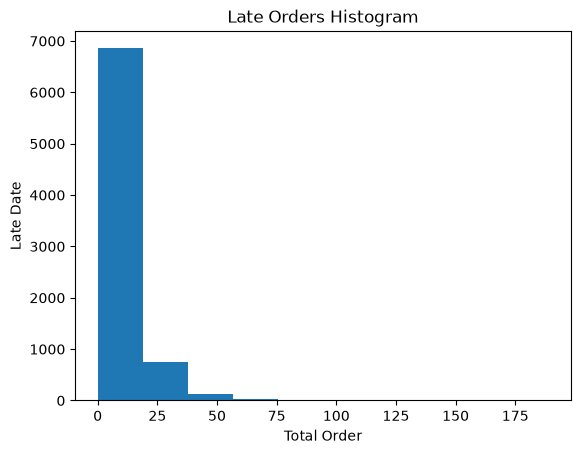

In [35]:
#DISTRIBUTION OF DELIVERY DELAYS
actual_date = pd.to_datetime(data["order_delivered_customer_date"])
estimated_date = pd.to_datetime(data["order_estimated_delivery_date"])
delay_days = (actual_date - estimated_date).dt.total_seconds()/86400
late_orders = delay_days[delay_days>0]
#STATISTIK
print(late_orders.describe())
#HISTOGRAM
plt.hist(late_orders)
plt.xlabel("Total Order")
plt.ylabel("Late Date")
plt.title("Late Orders Histogram")




Text(0.5, 1.0, '3')

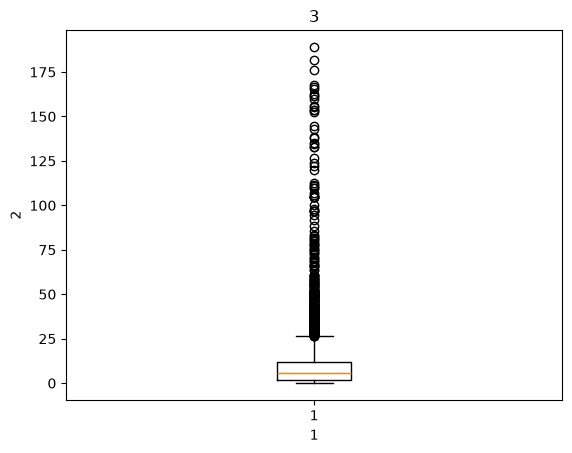

In [24]:
#BOXPLOT
plt.boxplot(late_orders)
plt.xlabel("1")
plt.ylabel("2")
plt.title("3")

In [36]:
print(type(late_orders))
print(late_orders.head())
print(delay_days.head())

<class 'pandas.Series'>
19    11.933171
24     9.919375
34     0.041262
40     7.791238
55     1.561644
dtype: float64
0    -7.107488
1    -5.355729
2   -17.245498
3   -12.980069
4    -9.238171
dtype: float64


In [39]:
Q1 = late_orders.quantile(0.25)
Q3 = late_orders.quantile(0.75)
IQR = Q3 - Q1
upperbound = Q3 + (1.5 * IQR)
outlier = (late_orders>upperbound).sum()
total = late_orders.count()
percentage = outlier/total*100
print(f"Total Orders that is more than {upperbound.round(0)} days late: {outlier}")
print(f"Total order: {total} orders")
print(f"Percentage of outlier: {percentage:.2f}%")

Total Orders that is more than 27.0 days late: 505
Total order: 7826 orders
Percentage of outlier: 6.45%


In [50]:
#MONTHLY TREND
monthly = pd.DataFrame({"purchase_date": pd.to_datetime(data.loc[delay_days.index,"order_purchase_timestamp"]), "delay_days": delay_days})
monthly["purchase_month"] = monthly["purchase_date"].dt.to_period("M")
late_orders_filtered = monthly[monthly["delay_days"]>0]
total_orders_monthly = monthly.groupby("purchase_month").size()
late_orders_monthly = late_orders_filtered.groupby("purchase_month").size().reindex(total_orders_monthly.index, fill_value=0)
late_rate_monthly = late_orders_monthly/total_orders_monthly*100

#print(total_orders_monthly.head())
#print(late_orders_monthly)
#print("----------------")
print(late_rate_monthly)


purchase_month
2016-09    100.000000
2016-10      1.132075
2016-12      0.000000
2017-01      3.066667
2017-02      3.206292
2017-03      5.577376
2017-04      7.859314
2017-05      3.610719
2017-06      3.859649
2017-07      3.434917
2017-08      3.315049
2017-09      5.204819
2017-10      5.292541
2017-11     14.311196
2017-12      8.380192
2018-01      6.563870
2018-02     15.987796
2018-03     21.362273
2018-04      5.310385
2018-05      8.238258
2018-06      1.361549
2018-07      4.483431
2018-08     10.392064
Freq: M, dtype: float64


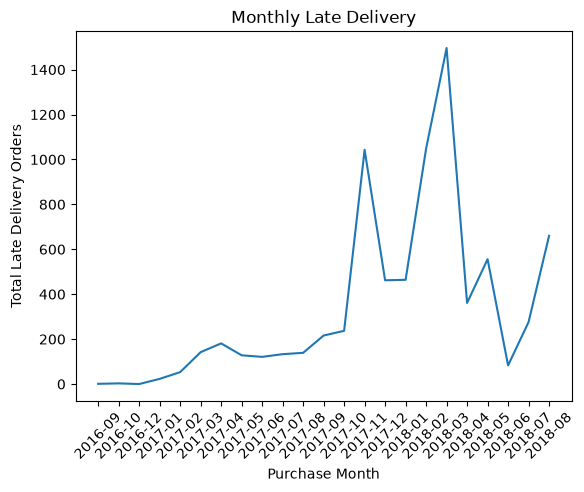

In [48]:
plt.plot(late_orders_monthly.index.astype(str), late_orders_monthly)
plt.xticks(rotation=45)
plt.xlabel("Purchase Month")
plt.ylabel("Total Late Delivery Orders")
plt.title("Monthly Late Delivery")
plt.show()

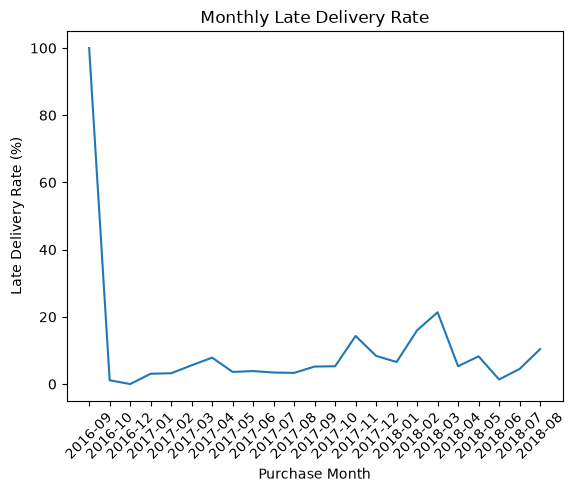

In [49]:
plt.plot(late_rate_monthly.index.astype(str), late_rate_monthly)
plt.xticks(rotation=45)
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.title("Monthly Late Delivery Rate")
plt.show()